# Homework 6: Root finding

**Course title:** Computer Simulation Methods in Physics (Phys 4071/5071; Fall 2025)  
**This homework assignment is due October 15, 2025 (extended deadline), at 8 am.**   
(Submission via the shared `GitHub` repository.)

**Before you submit your homework, make sure that you click `Kernel > Restart & Run All`**.

## Roots of a Polynomial

Consider the sixth-order polynomial

$$ P(x) = 924x^6 - 2772x^5 + 3150x^4 - 1680x^3 + 420x^2 - 42x + 1 \;.$$

1. How many roots do you expect? Why?
2. Make a plot of $P(x)$ from $x = 0$ to $x = 1$.
3. Find the approximate values for all real-valued roots of the polynomial by visual inspection.
4. Write a `Python` program to find all roots to at least ten decimal places of accuracy, using `Newton's method`. Do **not** use `Python` library functions for root finding.
5. Compare your roots with the results using an standard `Python package` for root-finding.

***Roots of a Polynomial 1.)***
---------------------------------------------------------------------------------------------
the sixth-order polynomial: $P(x) = 924x^{6} - 2772x^{5} + 3150x^{4} - 1680x^{3} + 420x^{2} - 42x + 1$ will have six roots 
because leading order of the polynomial is of $\text{order}-6$. 

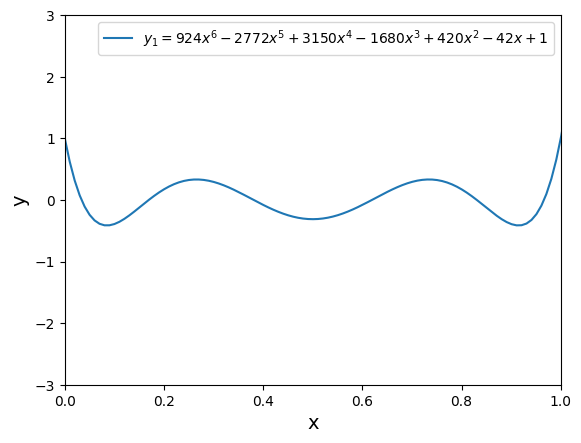

In [1]:
#Roots of a Polynomial 2.) 

import numpy as np
import matplotlib.pyplot as plt



def poly_6(x): 
    '''
     Calculates this 6th-order polynomial based on input gridspace x-values. 

    Parameters
    ----------
    x :  numpy array 
        Value or set of values that define the polynomial. 

    Returns
    -------
    numpy array 
        Return the value or values of the polynomial per each x. 
    '''
    return (924*x**6 - 2772*x**5 + 3150*x**4 - 1680*x**3 + 420*x**2 - 42*x + 1) 

x = np.linspace(0,10,1000) 
y1 = poly_6(x)


plt.plot(x, y1, label="$y_1 = 924x^{6} - 2772x^{5} + 3150x^{4} - 1680x^{3} + 420x^{2} - 42x + 1$")
plt.xlabel("x",fontsize = 14)
plt.xlim(0, 1)
plt.ylim(-3, 3)
plt.ylabel("y",fontsize = 14)
plt.legend()
plt.show()




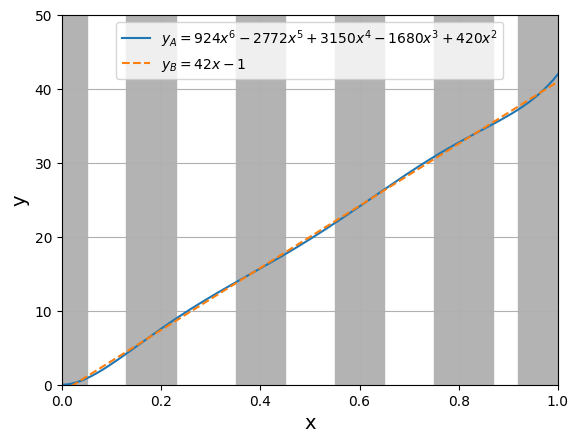

Roots were determined by visual inspection of the plot.
 Specifically the grey regions and using their limits for averaging; roots were then determined.

Roots tabulated form:
 x_1  x_2  x_3  x_4  x_5  x_6
0.03 0.18 0.40 0.60 0.81 0.96


In [2]:
#Roots of a polynomial 3.)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
from IPython.display import display, Markdown

def poly_A(x): 
    '''
     Calculates this 6th-order polynomial based on input gridspace x-values. 

    Parameters
    ----------
    x :  numpy array 
        Value or set of values that define the polynomial. 

    Returns
    -------
    numpy array 
        Return the value or values of the polynomial per each x. 
    '''
    return (924*x**6 - 2772*x**5 + 3150*x**4 - 1680*x**3 + 420*x**2) 

def poly_B(x): 
    '''
     Calculates this 1st-order polynomial based on input gridspace x-values. 

    Parameters
    ----------
    x :  numpy array 
        Value or set of values that define the polynomial. 

    Returns
    -------
    numpy array 
        Return the value or values of the polynomial per each x. (used in case for visual inspection apprach)
    '''
    return (42*x - 1) 


x_1 = np.linspace(0,10,1000) 
yA = poly_A(x)
yB = poly_B(x)



plt.plot(x, yA, label="$y_A = 924x^{6} - 2772x^{5} + 3150x^{4} - 1680x^{3} + 420x^{2} $")
plt.plot(x, yB,"--", label="$y_B = 42x - 1$")
plt.axvspan(0.0, 0.05, color="0.7", zorder=0)
plt.axvspan(0.13, 0.23, color="0.7", zorder=0)
plt.axvspan(0.35, 0.45, color="0.7", zorder=0)
plt.axvspan(0.55, 0.65, color="0.7", zorder=0)
plt.axvspan(0.75, 0.87, color="0.7", zorder=0)
plt.axvspan(0.92, 1.0, color="0.7", zorder=0)
plt.xlabel("x",fontsize = 14)
plt.xlim(0, 1)
plt.ylim(0, 50)
plt.ylabel("y",fontsize = 14)
plt.legend()
plt.grid(True)
plt.show()


Table = [] 
Table.append({
    "x_1": f"{(0.0 + 0.05)/(2.0):.2f}", 
    "x_2": f"{(0.13 + 0.23)/(2.0):.2f}", 
    "x_3": f"{(0.35 + 0.45)/(2.0):.2f}", 
    "x_4": f"{(0.55 + 0.65)/(2.0):.2f}", 
    "x_5": f"{(0.75 + 0.87)/(2.0):.2f}", 
    "x_6": f"{(0.92 + 1.0)/(2.0):.2f}"
})

y = pd.DataFrame(Table).to_string(index=False)
print("Roots were determined by visual inspection of the plot.\n Specifically the grey regions and using their limits for averaging; roots were then determined.")
print("\nRoots tabulated form:")
print(y)    







In [3]:
#Roots of a Polynomial 4.) 

import numpy as np
import matplotlib.pyplot as plt


def poly_6(x): 
    '''
     Calculates this 6th-order polynomial. 

    Parameters
    ----------
    x : float
        Value or set of values that define the polynomial. 

    Returns
    -------
    float
        Return the value or values of the polynomial per each x. 
    '''
    return (924*x**6 - 2772*x**5 + 3150*x**4 - 1680*x**3 + 420*x**2 - 42*x + 1) 

def der_poly_6(x): 
    '''
     Calculates this derivative of the 6th-order polynomial. 

    Parameters
    ----------
    x :  float 
        Value or set of values that define the derivative. 

    Returns
    -------
    float
        Return the value or values of the derivative for each x. 
    '''
    return (5544*x**5 - 13860*x**4 + 12600*x**3 - 5040*x**2 + 840*x - 42) 


def Newton(f, f_prime, x1): 
    '''
    Applies Newton's Method to iteratively approximate a root of a function.

    Parameters
    ----------
    f : function
        Function for which the root will be estimated.
    f_prime : function
        Derivative of function f.
    x1 : float
        Initial guess to start Newton's Method.

    Returns
    -------
    None
        Prints the iteration number, current estimate, and error estimate
        until the stopping criterion is met.
    '''
    error_estimate = 1 
    num_iter = 0 
    num_iter_max = 100 
    while error_estimate > 1e-5: 
        x2 = x1 - f(x1)/f_prime(x1)
        error_estimate = abs(x2-x1)
        print(f"x = {x1:.10f},  error estimate =  {error_estimate:1.8e}")
        x1=x2 
        num_iter+=1
        if num_iter > num_iter_max:
            break        

#Defining first guess
x1 = [0.05, 0.2, 0.4, 0.62, 0.79, 0.94] 
for i in range(len(x1)): 
    print(f"\n Root finding for set: {i}") 
    print(f"initial guess x1 = {x1[i]}")
    Newton(poly_6, der_poly_6, x1[i])





 Root finding for set: 0
initial guess x1 = 0.05
x = 0.0500000000,  error estimate =  2.17071689e-02
x = 0.0282928311,  error estimate =  5.08481210e-03
x = 0.0333776432,  error estimate =  3.85468476e-04
x = 0.0337631117,  error estimate =  2.13111907e-06

 Root finding for set: 1
initial guess x1 = 0.2
x = 0.2000000000,  error estimate =  3.58676804e-02
x = 0.1641323196,  error estimate =  5.21112018e-03
x = 0.1693434398,  error estimate =  5.18606867e-05
x = 0.1693953005,  error estimate =  6.30843208e-09

 Root finding for set: 2
initial guess x1 = 0.4
x = 0.4000000000,  error estimate =  1.99177345e-02
x = 0.3800822655,  error estimate =  6.07967017e-04
x = 0.3806902325,  error estimate =  1.74477212e-07

 Root finding for set: 3
initial guess x1 = 0.62
x = 0.6200000000,  error estimate =  6.90184294e-04
x = 0.6193098157,  error estimate =  2.22663959e-07

 Root finding for set: 4
initial guess x1 = 0.79
x = 0.7900000000,  error estimate =  5.24478081e-02
x = 0.8424478081,  error

In [4]:
#Roots of a Polynomial 5.) 

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import newton


def poly_6(x): 
    '''
     Calculates this 6th-order polynomial. 

    Parameters
    ----------
    x : float
        Value or set of values that define the polynomial. 

    Returns
    -------
    float
        Return the value or values of the polynomial per each x. 
    '''
    return (924*x**6 - 2772*x**5 + 3150*x**4 - 1680*x**3 + 420*x**2 - 42*x + 1) 

def der_poly_6(x): 
    '''
     Calculates this derivative of the 6th-order polynomial. 

    Parameters
    ----------
    x :  float 
        Value or set of values that define the derivative. 

    Returns
    -------
    float
        Return the value or values of the derivative for each x. 
    '''
    return (5544*x**5 - 13860*x**4 + 12600*x**3 - 5040*x**2 + 840*x - 42) 


#Defining first guess
x1 = [0.05, 0.2, 0.4, 0.62, 0.79, 0.94] 

for i in range(len(x1)): 
    print(f"\n Root finding for set: {i}") 
    print(f"initial guess x1 = {x1[i]}")
    print(newton(poly_6, x1[i], der_poly_6))



 Root finding for set: 0
initial guess x1 = 0.05
0.03376524289842399

 Root finding for set: 1
initial guess x1 = 0.2
0.16939530676686765

 Root finding for set: 2
initial guess x1 = 0.4
0.3806904069584

 Root finding for set: 3
initial guess x1 = 0.62
0.6193095930415999

 Root finding for set: 4
initial guess x1 = 0.79
0.8306046932331365

 Root finding for set: 5
initial guess x1 = 0.94
0.9662347571015685


## Lagrange Points

The [James Webb Space Telescope](https://webb.nasa.gov/content/about/orbit.html) (JWST) is located at the second Lagrange point L2 of the Sun-Earth system. This special orbit lets JWST stay in line with the Earth as it moves around the Sun. There are 3 other Lagrange points.

<img src="jwst.jpg" width="680">  

The Lagrange points L1 and L2 are nearly equally distant from Earth, with L1 between the Earth and Sun, and L2 on the opposite side of Earth from the Sun.

The equations for the distance $r$ from L1 ($-$) and L2 ($+$) to Earth only differ by a sign:

$$\frac{M_1}{(R\pm r)^2} \pm \frac{M_2}{r^2}=\left(\frac{M_1}{M_1+M_2}R \pm r\right)\frac{M_1+M_2}{R^3}$$

Here, $R$ is the distance between the Sun and Earth, and $M_1$ and $M_2$ are the mass of the Sun and Earth, respectively. We use mean distance for $R$ since the distance between the Sun and Earth is not constant.

(a) Write a `Python` program to solve for the distance $r$ from the Earth to $L_1$ and $L_2$, respectively using the secant method. Do not use solvers from `Python` packages. Compute the solutions with an accuracy of at least four significant digits. How far way is JWST from Earth? 

(b) Repeat part (b) using the bisection method. Compare the convergence pattern of the two solvers in a plot.

(c) For both L1 and L2, one finds the following approximation:

$$r \approx R \sqrt[3]{\frac{M_2}{3M_1}}$$

How accurate is this approximations?

The values of the parameters are:

\begin{align}
 M_1 &= 1.988 \cdot 10^{30} \,\mathrm{kg} \\
 M_2 &= 5.972 \cdot 10^{24} \,\mathrm{kg} \\
 R &= 1.471 \cdot 10^8 \, \mathrm{km}
\end{align}

In [5]:
#Lagrange Points Part a.) 
import numpy as np
import math 

#important constants 
M_1 = 1.988e30 
M_2 = 5.972e24 
R = 1.471e8 

#Functions Used 
def f1(r): 
    '''
    Calculates the function f1(r) used for root finding in a two-body problem.

    Parameters
    ----------
    r : float
        Radial distance variable used in the equation.

    Returns
    -------
    float
        Returns the evaluated result of the f1(r) function.
    '''
    return(((M_1 + M_2)/(R**3))*(((M_1)/(M_1 + M_2))*R - r) + (M_2/r**2) - (M_1/(R - r)**2))

def f2(r): 
    '''
    Calculates the function f2(r) used for root finding in a two-body problem.

    Parameters
    ----------
    r : float
        Radial distance variable used in the equation.

    Returns
    -------
    float
        Returns the evaluated result of the f2(r) function.
    '''
    return(((M_1 + M_2)/(R**3))*(((M_1)/(M_1 + M_2))*R + r) - (M_2/r**2) - (M_1/(R + r)**2))



#Secant Method Procedure 
def Secant(n, f):
    '''
    Applies the Secant Method to approximate a root of a nonlinear equation.

    Parameters
    ----------
    n : int
        Maximum number of Secant iterations allowed.
    f : function
        Function for which the root will be estimated.

    Returns
    -------
    None
        Prints the iteration number, estimated root, and error estimate
        until the stopping tolerance is reached.
    '''
    r0 = 1.0e6
    r1 = 2.0e6
    error_estimate = 1
    req_eps = 1e-9
    for i in range(1,n+1) :
        slope = (f(r1) - f(r0)) / (r1 - r0)
        r2 = r1 - f(r1) / slope
        error_estimate = abs(r2 - r1)
        print(f"iter #{i} \t est. root: {r2:.4g}\test. error: {error_estimate:.4g}")
        r0 = r1
        r1 = r2
        if error_estimate < req_eps:
            break
          
    

#L1 and L2 cases 
print(f"r from L_1 case: \n")
Secant(300, f1)

print(f"\n r from L_2 case: \n")
Secant(300, f2)


r from L_1 case: 

iter #1 	 est. root: 1.639e+06	est. error: 3.608e+05
iter #2 	 est. root: 1.415e+06	est. error: 2.24e+05
iter #3 	 est. root: 1.473e+06	est. error: 5.745e+04
iter #4 	 est. root: 1.467e+06	est. error: 5655
iter #5 	 est. root: 1.467e+06	est. error: 207.8
iter #6 	 est. root: 1.467e+06	est. error: 0.8205
iter #7 	 est. root: 1.467e+06	est. error: 0.000115
iter #8 	 est. root: 1.467e+06	est. error: 8.149e-09
iter #9 	 est. root: 1.467e+06	est. error: 3.958e-09
iter #10 	 est. root: 1.467e+06	est. error: 1.63e-09
iter #11 	 est. root: 1.467e+06	est. error: 9.313e-10

 r from L_2 case: 

iter #1 	 est. root: 1.651e+06	est. error: 3.491e+05
iter #2 	 est. root: 1.424e+06	est. error: 2.268e+05
iter #3 	 est. root: 1.483e+06	est. error: 5.844e+04
iter #4 	 est. root: 1.477e+06	est. error: 5850
iter #5 	 est. root: 1.477e+06	est. error: 219.8
iter #6 	 est. root: 1.477e+06	est. error: 0.9045
iter #7 	 est. root: 1.477e+06	est. error: 0.0001349
iter #8 	 est. root: 1.477e+06	

In [6]:
#Lagrange Points Part b.) Bisection Method 

import numpy as np
import math 


def Bisection(f, r1, r2, epsilon, N): 
    '''
    Applies the Bisection Method to approximate the same roots for the two-body problem.

    Parameters
    ----------
    f : function
        Function for which the root will be estimated.
    r1 : float
         endpoint of the initial interval where a sign change occurs.
    r2 : float
         endpoint of the initial interval where a sign change occurs.
    epsilon : float
        Desired tolerance for convergence.
    N : int
        Maximum number of iterations allowed.

    Returns
    -------
    None
        Prints the iteration number, estimated root, and error estimate
        until the stopping tolerance is met.
    '''
    #Fail Condition
    if f(r1)*f(r2) >= 0: 
        print("f(r1) and f(r2) must have opposite signs") 
        return None
    #Initialize iterator and error calculation
    n = 0
    error_est = abs(r2 - r1)
    #Begin looping 
    while error_est > epsilon and n < N: 
        #midpoint calculation 
        r3 = (r1 + r2)/2.0 
        #Conditional for convergence 
        if abs(f(r3)) < epsilon: 
            break 
        elif f(r1)*f(r3) < 0: 
            r2 = r3 
        else: 
            r1 = r3 
        print(f"iter #{n} \t est. root: {r3:.4g}\test. error: {error_est:.4g}")
        error_est = abs(r2 - r1)
        n += 1
    

    

#L1 and L2 cases 
print(f"r from L_1 case (Bisection): \n")
Bisection(f1, 1.0e6, 2.0e6, 1e-9, 400)

print(f"\n r from L_2 case (Bisection): \n")
Bisection(f2, 1.0e6, 2.0e6, 1e-9, 400)
    


r from L_1 case (Bisection): 

iter #0 	 est. root: 1.5e+06	est. error: 1e+06
iter #1 	 est. root: 1.25e+06	est. error: 5e+05
iter #2 	 est. root: 1.375e+06	est. error: 2.5e+05
iter #3 	 est. root: 1.438e+06	est. error: 1.25e+05
iter #4 	 est. root: 1.469e+06	est. error: 6.25e+04
iter #5 	 est. root: 1.453e+06	est. error: 3.125e+04
iter #6 	 est. root: 1.461e+06	est. error: 1.562e+04
iter #7 	 est. root: 1.465e+06	est. error: 7812
iter #8 	 est. root: 1.467e+06	est. error: 3906
iter #9 	 est. root: 1.466e+06	est. error: 1953
iter #10 	 est. root: 1.466e+06	est. error: 976.6
iter #11 	 est. root: 1.467e+06	est. error: 488.3
iter #12 	 est. root: 1.467e+06	est. error: 244.1
iter #13 	 est. root: 1.467e+06	est. error: 122.1
iter #14 	 est. root: 1.467e+06	est. error: 61.04
iter #15 	 est. root: 1.467e+06	est. error: 30.52
iter #16 	 est. root: 1.467e+06	est. error: 15.26
iter #17 	 est. root: 1.467e+06	est. error: 7.629
iter #18 	 est. root: 1.467e+06	est. error: 3.815
iter #19 	 est. roo


 As seen from both plots visual inspection details that secant method converges faster, which means it'll find root quicker if converges.


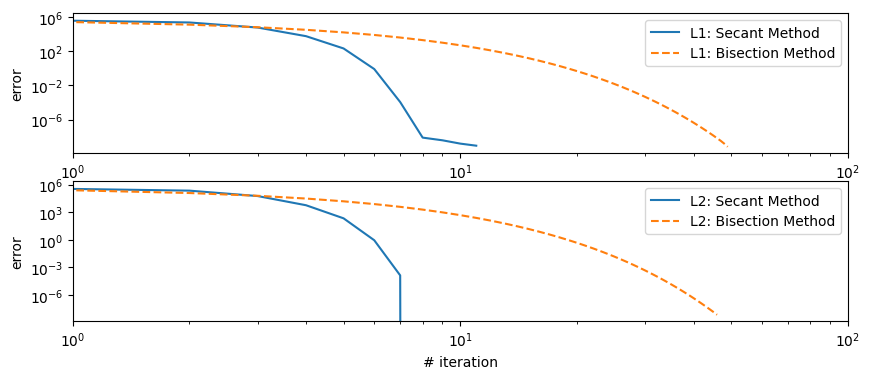

In [7]:
#Lagrange Points Part b.) Covergence Plots 
import matplotlib.pyplot as plt 
import numpy as np
import math 


# 2 row, 2 columns of subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 4))

def Sec_plot(n, f):
    '''
    Computes error estimates for each iteration of the Secant Method
    to enable convergence plotting.

    Parameters
    ----------
    n : int
        Maximum number of Secant iterations allowed.
    f : function
        Function for which the root will be estimated.

    Returns
    -------
    list, list
        Returns two lists:
        - secant_error: error estimate at each iteration.
        - secant_iterator: corresponding iteration numbers.
    '''
    r0 = 1.0e6
    r1 = 2.0e6
    error_estimate = 1
    req_eps = 1e-9
    #Lists for secant plotting
    secant_error = [] 
    secant_iterator = [] 
    for i in range(1,n+1):
        slope = (f(r1) - f(r0)) / (r1 - r0)
        r2 = r1 - f(r1) / slope
        error_estimate = abs(r2 - r1)
        secant_error.append(error_estimate)
        secant_iterator.append(i)
        r0 = r1
        r1 = r2
        if error_estimate < req_eps:
            break
    return secant_error, secant_iterator 


def Bis_plot(f, r1, r2, epsilon, N): 
    '''
    Computes error estimates for each iteration of the Bisection Method
    to enable convergence plotting.

    Parameters
    ----------
    f : function
        Function for which the root will be estimated.
    r1 : float
       endpoint of the initial interval.
    r2 : float
       endpoint of the initial interval.
    epsilon : float
        Desired tolerance for convergence.
    N : int
        Maximum number of iterations allowed.

    Returns
    -------
    list, list or None
        Returns two lists:
        - Bis_error: error estimate at each iteration.
        - Bis_iterator: corresponding iteration numbers.
        Returns None if f(r1) and f(r2) do not have opposite signs.
    '''
    #Fail Condition
    if f(r1)*f(r2) >= 0: 
        print("f(r1) and f(r2) must have opposite signs") 
        return None
    #Initialize iterator and error calculation
    n = 0
    error_est = abs(r2 - r1)
    #Lists for bisection plotting
    Bis_error = [] 
    Bis_iterator = [] 
    #Begin looping 
    while error_est > epsilon and n < N: 
        #midpoint calculation 
        r3 = (r1 + r2)/2.0 
        #Conditional for convergence 
        if abs(f(r3)) < epsilon: 
            break 
        elif f(r1)*f(r3) < 0: 
            r2 = r3 
        else: 
            r1 = r3 
        error_est = abs(r2 - r1)
        Bis_error.append(error_est)
        Bis_iterator.append(n)
        n += 1
    return Bis_error, Bis_iterator 




#L1 and L2 cases from secant
sec_errr_a, sec_ia = Sec_plot(300, f1)
sec_errr_b, sec_ib = Sec_plot(300, f2)


#L1 and L2 cases from bisection 
Bis_er_a, Bis_ia = Bis_plot(f1, 1.0e6, 2.0e6, 1e-9, 400)
Bis_er_b, Bis_ib = Bis_plot(f2, 1.0e6, 2.0e6, 1e-9, 400)




axes[0].loglog(sec_ia, sec_errr_a, label = "L1: Secant Method")    
axes[0].loglog(Bis_ia, Bis_er_a, "--", label = "L1: Bisection Method") 
axes[0].set_xlabel("# iteration")
axes[0].set_ylabel("error")
axes[0].set_xlim(1, 100)
axes[0].legend(loc="best")


axes[1].loglog(sec_ib, sec_errr_b, label = "L2: Secant Method")    
axes[1].loglog(Bis_ib, Bis_er_b, "--", label = "L2: Bisection Method") 
axes[1].set_xlabel("# iteration")
axes[1].set_ylabel("error")
axes[1].set_xlim(1, 100)
axes[1].legend(loc="best")


print("\n As seen from both plots visual inspection details that secant method converges faster, which means it'll find root quicker if converges.") 



In [8]:
#Lagrange Points Part c.) 
import numpy as np
import math 

#estimate based on approx works both L1 and L2
R_est = R*pow(M_2/(3.0*M_1), 1.0/3.0)
print(f"root approx for both L1 and L2 approaches: r = {R_est: .4g}")
print("\n By inspection for both methods, the roots (L1 and L2 approaches) match the approximated root") 

root approx for both L1 and L2 approaches: r =  1.472e+06

 By inspection for both methods, the roots (L1 and L2 approaches) match the approximated root


## Nonlinear circuits

Consider the following simple circuit, a variation on the classic Wheatstone bridge:

<img src="nlcircuit.jpg" width="304">  

The resistors obey the normal Ohm law, but the diode obeys the diode equation:

$$ 
I = I_0 \left ( e^{V/V_T} -1 \right )  
$$    ,

where $V$ is the voltage across the diode and $I_0$ and $V_T$ are constants. Kirchhoff's current law states that the total net current lowing into or out of every vortex in a circuit must be zero. Applying the law to voltage $V_1$ in the circuit above, one gets

\begin{align}
{V_1 − V_+ \over R_1}  + {V_1 \over R_2}  + I_0 \left (e^{( V_1−V_2)/V_T } − 1 \right )  &= 0 \\
{V_2 − V_+ \over R_3}  + {V_2 \over R_4}  + I_0 \left (1 - e^{( V_1−V_2)/V_T } \right )  &= 0
\end{align}

(a) Solve the two nonlinear equations for the voltages $V_1$ and $V_2$ with the conditions

$$ 
V_+ = 5V~,~R_1 =1k\Omega~,~ R_2 =4k\Omega~,~R_3 =3k\Omega~,~R_4 =2k\Omega~,~I_0 =3nA~,~V_T = 0.05V
$$

Use Newton’s method for several nonlinear equations to solve these equations and determine the voltages $V_n$. 

(b) The electronic engineer’s rule of thumb for diodes is that the voltage across a (forward biased) diode is always about 0.6 volts. Confirm that your results agree with this rule.

**Nonlinear Circuits Part a.) Finding Derivatives**
----------------------------------------------------------------------------------------------

$
f_1(V_1, V_2) = \frac{V_1 - V_+}{R_1} + \frac{V_1 + V_T}{R_2} + I_0 \left( e^{\frac{(V_1 - V_2)}{V_T}} - 1 \right)
$

$
f_2(V_1, V_2) = \frac{V_2 - V_+}{R_3} + \frac{V_2 - V_T}{R_4} + I_0 \left( 1 - e^{\frac{(V_1 - V_2)}{V_T}} \right)
$

$
\mathbf{J} =
\begin{pmatrix}
\frac{\partial f_1}{\partial V_1} & \frac{\partial f_1}{\partial V_2} \\
\frac{\partial f_2}{\partial V_1} & \frac{\partial f_2}{\partial V_2}
\end{pmatrix}
$

$
\frac{\partial f_1}{\partial V_1} =
\frac{1}{R_1} + \frac{1}{R_2} + \frac{I_0}{V_T} e^{\frac{(V_1 - V_2)}{V_T}}
$

$
\frac{\partial f_1}{\partial V_2} =
 -\frac{I_0}{V_T} e^{\frac{(V_1 - V_2)}{V_T}}
$

$
\frac{\partial f_2}{\partial V_1} =
 -\frac{I_0}{V_T} e^{\frac{(V_1 - V_2)}{V_T}}
$

$
\frac{\partial f_2}{\partial V_2} =
\frac{1}{R_3} + \frac{1}{R_4} + \frac{I_0}{V_T} e^{\frac{(V_1 - V_2)}{V_T}}
$


In [9]:
# Nonlinear Circuits Part a.) 

import numpy as np
from numpy.linalg import solve


#Define Constants 
V_plus = 5.0 
R_1 = 1e3 
R_2 = 4e3
R_3 = 3e3 
R_4 = 2e3
I_o = 3e-9 
V_T = 0.05 


#Nonlinear function 1
def f_1(V1, V2): 
    '''
    Defines the first nonlinear circuit equation involving the diode equation.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage  2.

    Returns
    -------
    float
        Returns the evaluated result of the first nonlinear function f_1.
    '''
    return (((V1 - V_plus)/(R_1))  +  ((V1 + V_T)/(R_2)) + I_o*(np.exp((V1 - V2)/(V_T)) - 1.0)) 

#Nonlinear function 2
def f_2(V1, V2): 
    '''
    Defines the second nonlinear circuit equation involving the diode equation.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage 2.

    Returns
    -------
    float
        Returns the evaluated result of the second nonlinear function f_2.
    '''
    return (((V2 - V_plus)/(R_3))  +  ((V2 - V_T)/(R_4)) + I_o*(1.0 - np.exp((V1 - V2)/(V_T)))) 


#Jacobian terms 
def d_f1_V1(V1,V2): 
    '''
    Computes the partial derivative of f_1 with respect to V1.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage 2.

    Returns
    -------
    float
        Partial derivative value.
    '''
    return ((1.0/R_1) + (1.0/R_2) + (I_o/V_T)*(np.exp((V1 - V2)/(V_T))))
    

def d_f1_V2(V1, V2): 
    '''
    Computes the partial derivative of f_1 with respect to V2.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage 2.

    Returns
    -------
    float
        Partial derivative value.
    '''
    return((-I_o/V_T)*(np.exp((V1 - V2)/(V_T))))


def d_f2_V1(V1, V2): 
    '''
    Computes the partial derivative of f_2 with respect to V1.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage 2.

    Returns
    -------
    float
        Partial derivative value.
    '''
    return((-I_o/V_T)*(np.exp((V1 - V2)/(V_T))))



def d_f2_V2(V1,V2): 
    '''
    Computes the partial derivative of f_2 with respect to V2.

    Parameters
    ----------
    V1 : float
        Voltage 1.
    V2 : float
        Voltage 2.

    Returns
    -------
    float
        Partial derivative value.
    '''
    return ((1.0/R_3) + (1.0/R_4) + (I_o/V_T)*(np.exp((V1 - V2)/(V_T))))



# starting point
V1_i = 2.0
V2_i = 1.5
for i in range(0, 30, 1):
    
    # set the vector
    v = -np.array([f_1(V1_i, V2_i),
                   f_2(V1_i, V2_i)], float)

    # set the Jacobian matrix
    J = np.array([[d_f1_V1(V1_i,V2_i), d_f1_V2(V1_i, V2_i)], 
                  [d_f2_V1(V1_i, V2_i), d_f2_V2(V1_i,V2_i)]], float)

    # solve the linear system
    delta = solve(J,v)

    # obtain updated estimate for the root
    V1 = V1_i + delta[0]
    V2 = V2_i + delta[1]    
    print(f"V1 = {V1:1.10e}, V2 = {V2:1.10e}")

    # update current point
    V1_i=V1
    V2_i=V2


print(f"\n Final V1 = {V1_i},  V2 = {V2_i}")





V1 = 3.5517900736e+00, V2 = 2.6873148895e+00
V1 = 3.5319083880e+00, V2 = 2.7171374180e+00
V1 = 3.5122418285e+00, V2 = 2.7466372573e+00
V1 = 3.4931688138e+00, V2 = 2.7752467792e+00
V1 = 3.4756592771e+00, V2 = 2.8015110844e+00
V1 = 3.4617975240e+00, V2 = 2.8223037139e+00
V1 = 3.4542487253e+00, V2 = 2.8336269120e+00
V1 = 3.4524696781e+00, V2 = 2.8362954828e+00
V1 = 3.4523887006e+00, V2 = 2.8364169490e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.4523885422e+00, V2 = 2.8364171868e+00
V1 = 3.452

In [10]:
# Nonlinear Circuits Part b.) 

import numpy as np
from numpy.linalg import solve

V_diode = 0.6 

V_across = V1_i - V2_i 

tolerance = 1e-1

Approx_check = abs(V_diode - V_across) < tolerance 

if Approx_check: 
    print("Voltage across is approx diode voltage") 
else: 
    print("Volatage across isn't close to diode voltage") 


Voltage across is approx diode voltage
